In [1]:
import sys
import os
os.environ["OMP_NUM_THREADS"] = "1"
import numpy as np
import matplotlib.pyplot as plt
from time import sleep

#from numba import jit
from jax import config
config.update("jax_enable_x64", True)
import jax.numpy as jnp
from jax import grad, jit, vmap, lax, ShapeDtypeStruct, pure_callback, debug

import petitRADTRANS.jax_radtrans as jrt

from petitRADTRANS.fortran_radtrans_core import fortran_radtrans_core
from petitRADTRANS.jax_physics import compute_planck_function_integral
from petitRADTRANS.fortran_radtrans_core import math as fmath
from petitRADTRANS.fortran_radtrans_core import physics as fphysics
import petitRADTRANS.physical_constants as cst 

from petitRADTRANS.radtrans import Radtrans
from petitRADTRANS.retrieval.parameter import Parameter
from petitRADTRANS.retrieval.models import emission_model_diseq, guillot_emission
import petitRADTRANS.plotlib.style as ps
ps.set_petitradtrans_plot_style()
path_input_data = "/Users/nasedkin/python-packages/petitRADTRANS/input_data/"
buffer = np.genfromtxt(os.path.join(path_input_data, 'opa_input_files', 'g_comb_grid.dat'))


INFO:jax._src.xla_bridge:Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/opt/anaconda3/envs/jaxprt/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache), 'libtpu.so' (no such file), '/usr/local/lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache)


Using pRT Plotting style!


In [ ]:
# Constants
ITER_SCAT = 1000
TINIEST = jnp.finfo(jnp.float64).tiny
PI_4 = 4.0 * jnp.pi
N_ITERATIONS_MIN = 9
CONVERGENCE_THRESHOLD = 1e-3
HUGE = jnp.sqrt(jnp.finfo(jnp.float64).max)

@jit
def m_approximate_ng_source(source_n, source_n1, source_n2, source_n3, source):
    n_layers = source_n.shape[0]
    source_buff = jnp.zeros(n_layers)

    Q1 = source_n - (2.0 * source_n1) + source_n2
    Q2 = source_n - source_n1 - source_n2 + source_n3
    Q3 = source_n - source_n1

    Q1 = Q1.at[0].set(0.0)
    Q2 = Q2.at[0].set(0.0)
    Q3 = Q3.at[0].set(0.0)

    A1 = jnp.minimum(jnp.sum(Q1 * Q1), HUGE)
    A2 = jnp.minimum(jnp.sum(Q2 * Q1), HUGE)
    B1 = jnp.minimum(jnp.sum(Q1 * Q2), HUGE)
    B2 = jnp.minimum(jnp.sum(Q2 * Q2), HUGE)
    C1 = jnp.minimum(jnp.sum(Q1 * Q3), HUGE)
    C2 = jnp.minimum(jnp.sum(Q2 * Q3), HUGE)

    AB_denominator = A1 * B2 - A2 * B1

    def nan_handling():
        return source
    
    def compute_source():
        temp_1 = (C1 * B2 - C2 * B1) / AB_denominator
        temp_2 = (C2 * A1 - C1 * A2) / AB_denominator

        return jnp.maximum((1.0 - temp_1 - temp_2) * source_n 
                           + temp_1 * source_n1
                           + temp_2 * source_n2,
                           0.0)


    cond_skip_ng = (AB_denominator < TINIEST) | \
                   (jnp.abs(A1) < 1e-250) | (jnp.abs(A2) < 1e-250) | \
                   (jnp.abs(B1) < 1e-250) | (jnp.abs(B2) < 1e-250) | \
                   (jnp.abs(C1) < 1e-250) | (jnp.abs(C2) < 1e-250)
    
    source_buff = lax.cond(
            cond_skip_ng,
            nan_handling,
            compute_source
        )
    return source_buff


def solve_tridiagonal_system(a, b, c, d):
    result_shape = ShapeDtypeStruct(d.shape, d.dtype)
    return pure_callback(fmath.solve_tridiagonal_system, result_shape, a, b, c, d)

@jit
def ng_acceleration(
        i_iter_scat, 
        source, 
        l, 
        i, 
        source_planet_scat_n,
        source_planet_scat_n1, 
        source_planet_scat_n2, 
        source_planet_scat_n3):
    
    # Ng acceleration
    def true_fun(vals):
        source, l, i, source_planet_scat_n, source_planet_scat_n1, source_planet_scat_n2, source_planet_scat_n3 = vals
        source_planet_scat_n = source[:, l, i]
        source = source.at[:, l, i].set(m_approximate_ng_source(
            source_planet_scat_n, 
            source_planet_scat_n1, 
            source_planet_scat_n2, 
            source_planet_scat_n3, 
            source[:, l, i]
        ))
        return source, source[:, l, i], source_planet_scat_n

    # Default to just passing the input arrays
    def false_fun(vals):
        source, l, i, source_planet_scat_n, source_planet_scat_n1, source_planet_scat_n2, source_planet_scat_n3 = vals
        return source, source[:, l, i], source_planet_scat_n

    # Only accelerate every 4th iteration
    condition = (((i_iter_scat+1) % 4 == 0) & (i_iter_scat>0))
    source, r, source_planet_scat_n = lax.cond(
        condition,
        true_fun,
        false_fun, 
        (source, l, i, source_planet_scat_n, source_planet_scat_n1, source_planet_scat_n2, source_planet_scat_n3)
    )
    return source, r, source_planet_scat_n

def compute_feautrier_radiative_transfer(
    frequencies_bin_edges, 
    temperatures, 
    weights_gauss, 
    emission_cos_angles, 
    emission_cos_angles_weights,
    optical_depths, 
    photon_destruction_probabilities, 
    emission_geometry, 
    stellar_intensity,
    star_irradiation_cos_angle, 
    reflectances, 
    emissivities
):
    # Constants
    # TODO: get from single shape call
    n_angles = emission_cos_angles.shape[0]
    n_frequencies_bin_edges = frequencies_bin_edges.shape[0]
    n_layers = temperatures.shape[0]
    n_g = weights_gauss.shape[0]
    
    surf_refl_2 = 2 * reflectances
    mu_weight = emission_cos_angles * emission_cos_angles_weights

    # Initialize arrays
    I_star_calc = jnp.zeros((n_g, n_layers, n_angles, n_frequencies_bin_edges - 1))
    J_star_ini = jnp.zeros((n_g, n_layers, n_frequencies_bin_edges - 1))

    # Reshape photon_destruction_probabilities
    photon_destruction_probabilities_ = jnp.transpose(photon_destruction_probabilities, (2, 0, 1))

    # Compute Planck function integral
    # Definitely not planck function. Checked w fortran version.
    planck = compute_planck_function_integral(temperatures, frequencies_bin_edges)

    # Geometry coefficient
    # TODO: rewrite to take in geometry coefficient as an argument.
    if emission_geometry == 'dayside_ave':
        geometry_coefficient = 0.5
    elif emission_geometry == 'planetary_ave':
        geometry_coefficient = 0.25
    elif emission_geometry == 'non-isotropic':
        geometry_coefficient = -1.0
    else:
        raise ValueError("Invalid geometry")

    # Stellar attenuation calculation
    if geometry_coefficient > 0:
        for i in range(n_frequencies_bin_edges - 1):
            for i_mu in range(n_angles):
                I_star_calc = I_star_calc.at[:, :, i_mu, i].set(
                    geometry_coefficient 
                    * jnp.abs(stellar_intensity[i]) 
                    * jnp.exp(-optical_depths[:, i, :]/ emission_cos_angles[i_mu])
                    )
                J_star_ini = J_star_ini.at[:, :, i].add(
                    0.5 * I_star_calc[:, :, i_mu, i] * emission_cos_angles_weights[i_mu]
                    )
    else:
        J_star_ini = jnp.abs(stellar_intensity[None, None, :]
                             / (4.0 * jnp.exp(-jnp.transpose(optical_depths[:, :, :],(0,2,1)) / star_irradiation_cos_angle)))
                        

    # Prevent issues with negative or 0 photon destruction probabilities
    photon_destruction_probabilities_ = jnp.where(photon_destruction_probabilities_ < 1e-10, 
                                                  1e-10, 
                                                  photon_destruction_probabilities_)

    # Initialize surface emission and reflection
    I_surface_no_scattering = jnp.zeros((n_g, n_frequencies_bin_edges - 1))
    for i in range(n_frequencies_bin_edges - 1):
        I_surface_emission = emissivities[i] * planck[-1, i]
        if emission_geometry != 'non-isotropic':
            I_surface_reflection = surf_refl_2[i] * jnp.sum(I_star_calc[:, -1, :, i] * mu_weight)
        else:
            I_surface_reflection = reflectances[i] * J_star_ini[:, -1, i] * 4.0 * star_irradiation_cos_angle
        I_surface_no_scattering = I_surface_no_scattering.at[:, i].set(I_surface_emission + I_surface_reflection)

    # Main loop over frequencies
    flux = _internal_feautrier_radiative_transer(
        planck,
        optical_depths,
        photon_destruction_probabilities_,
        J_star_ini,
        I_surface_no_scattering,
        surf_refl_2,
        emission_cos_angles,
        emission_cos_angles_weights,
        mu_weight,
        weights_gauss
        )
    return flux


def _internal_feautrier_radiative_transer(
        planck,
        optical_depths,
        photon_destruction_probabilities_,
        J_star_ini,
        I_surface_no_scattering,
        surf_refl_2,
        emission_cos_angles,
        emission_cos_angles_weights,
        mu_weight,
        weights_gauss
    ):

    # Constants
    n_layers, n_g, n_frequencies_bin_edges = photon_destruction_probabilities_.shape
    n_frequencies_bin_edges+=1
    n_angles = emission_cos_angles.shape[0]

    inv_del_tau_min = 1e10
    inv_del_tau_min_half = inv_del_tau_min * 0.5
    mu_double = emission_cos_angles * 2

    # Initialize arrays
    flux = jnp.zeros((n_frequencies_bin_edges - 1))
    source = jnp.zeros((n_layers, n_g, n_frequencies_bin_edges-1))

    J_planet_scat = jnp.zeros((n_layers, n_g, n_frequencies_bin_edges - 1))
    I_plus_surface = jnp.zeros((n_angles, n_g, n_frequencies_bin_edges - 1))

    # Tridiagonal matrix
    b = jnp.ones((n_layers, n_angles))
    c = jnp.zeros((n_layers, n_angles))
    a = jnp.zeros((n_layers, n_angles))
    f1 = jnp.zeros(n_layers)
    f2_struct = jnp.zeros((n_layers-2, n_angles))
    f3_struct = jnp.zeros((n_layers-2, n_angles))

    # Flux arrays
    I_H = jnp.zeros((n_layers, n_angles))
    I_J = jnp.zeros((n_layers, n_angles))

    # Source arrays
    lambda_loc = jnp.zeros((n_layers, n_g, n_frequencies_bin_edges - 1))
    source_planet_scat_n = jnp.zeros(n_layers)
    source_planet_scat_n1 = jnp.zeros(n_layers)
    source_planet_scat_n2 = jnp.zeros(n_layers)
    source_planet_scat_n3 = jnp.zeros(n_layers)
    
    # Main loop over frequencies
    for i in range(n_frequencies_bin_edges - 1):
        r = planck[:, i]
        for l in range(n_g):
            source = source.at[:, l, i].set(
                (photon_destruction_probabilities_[:, l, i] * planck[:, i]) +
                ((1.0 - photon_destruction_probabilities_[:, l, i]) * J_star_ini[l, :, i])
            )
            flux_tmp = 0.0

            # Calculate tau derivative
            dtau_1_level = optical_depths[l, i, 1:] - optical_depths[l, i, :-1]
            dtau_1_level = jnp.where(jnp.abs(dtau_1_level) < TINIEST, TINIEST, dtau_1_level)
            dtau_2_level = optical_depths[l, i, 2:]-optical_depths[l, i, 0:-2]
            dtau_2_level = jnp.where(jnp.abs(dtau_2_level) < TINIEST, TINIEST, dtau_2_level)
            
            # Boundary treatment, setting up arrays for tridag solver
            for j in range(n_angles):
                f1 = f1.at[:-1].set(emission_cos_angles[j] / dtau_1_level)
                f1 = jnp.where(f1 > inv_del_tau_min, inv_del_tau_min, f1)
   
                # Set zeroth elements
                b = b.at[0, j].set(1. + (2. * f1[0] * (1. + f1[0])))
                c = c.at[0, j].set(-2. * (f1[0] ** 2.))
                a = a.at[0, j].set(0.0)
                lambda_loc = lambda_loc.at[0, l, i].add(emission_cos_angles_weights[j] / b[0, j])
                
                # Set middle element range
                f1 = f1.at[1:-1].set(mu_double[j] / dtau_2_level)
                f2 = emission_cos_angles[j] / dtau_1_level
                f3 = emission_cos_angles[j] / dtau_1_level

                # Instability test
                f1 = jnp.where(f1 > inv_del_tau_min_half, inv_del_tau_min_half, f1)
                f2 = jnp.where(f2 > inv_del_tau_min, inv_del_tau_min, f2)
                f3 = jnp.where(f3 > inv_del_tau_min, inv_del_tau_min, f3)

                f2_struct = f2_struct.at[:, j].set(f2[1:])
                f3_struct = f3_struct.at[:, j].set(f3[:-1])

                b = b.at[1:-1, j].set(1.0 + (f1[1:-1] * (f2[1:] + f3[:-1])))
                c = c.at[1:-1, j].set(-f1[1:-1] * f2[1:])
                a = a.at[1:-1, j].set(-f1[1:-1] * f3[:-1])
                lambda_loc = lambda_loc.at[1:-1, l, i].add(
                    emission_cos_angles_weights[j] 
                    / (1. + (f1[1:-1] * (f2[1:] + f3[:-1]))))

                # Set last element
                f1 = f1.at[-1].set(emission_cos_angles[j] / dtau_1_level[-1])
                f1 = jnp.where(f1 > inv_del_tau_min, inv_del_tau_min, f1)
                lambda_loc = lambda_loc.at[-1, l, i].add(
                    emission_cos_angles_weights[j] 
                    / (1. + (2. * (f1[-1] ** 2.))))

            # Iterate flux calculation until convergence
            def scattering_condition(state):
                conv_val = state[0]
                i_iter_scat = state[1]
                converged = ((i_iter_scat < N_ITERATIONS_MIN) |
                              (conv_val > CONVERGENCE_THRESHOLD))
                return converged
            
            #@jit
            def scattering_function(state):
                (conv_val,
                i_iter_scat,
                i,
                l,
                flux,
                I_surface_no_scattering,
                I_plus_surface,
                surf_refl_2,
                I_J,
                I_H,
                a,
                b,
                c,
                r,
                f2_struct,
                f3_struct,
                flux_tmp,
                mu_weight,
                photon_destruction_probabilities_,
                planck,
                J_star_ini,
                J_planet_scat,
                lambda_loc,
                source,
                source_planet_scat_n3,
                source_planet_scat_n2,
                source_planet_scat_n1,
                source_planet_scat_n,
                weights_gauss
                ) = state
                
                
                inv_del_tau_min = 1e10
                #inv_del_tau_min_half = inv_del_tau_min * 0.5
                #mu_double = emission_cos_angles * 2
                
                # Angles loop to set up fluxes
                for j in range(n_angles):
                    I_minus = (I_surface_no_scattering[l, i] +
                               (surf_refl_2[i] * jnp.sum(I_plus_surface[:, l, i] * mu_weight)))
                    r = r.at[-1].set(0.5 * (I_plus_surface[j, l, i] + I_minus))

                    I_J = I_J.at[:, j].set(solve_tridiagonal_system(a[:, j], b[:, j], c[:, j], r))
                    I_H = I_H.at[0, j].set(-I_J[0,j])
                    
                    deriv1 = f2_struct[:, j] * (I_J[2:n_layers, j] - I_J[1:n_layers-1, j])
                    deriv2 = f3_struct[:, j] * (I_J[1:n_layers-1, j] - I_J[:n_layers-2, j])

                    I_H = I_H.at[1:-1, j].set(-0.5 * (deriv1 + deriv2))
                    I_plus_surface = I_plus_surface.at[j, l, i].set(I_J[n_layers, j]-deriv1[n_layers - 1])
                    I_H = I_H.at[-1:, j].set(0.0)
                

                # Test convergence
                flux_tmp_old = flux_tmp
                flux_tmp = jnp.sum(flux_tmp - I_H[0, j] * mu_weight[j])
                conv_val = jnp.abs(1.0 - flux_tmp_old / flux_tmp)
                
                # Calculate the source function
                J_bol_g = jnp.sum(I_J * emission_cos_angles_weights, axis=1)
                J_planet_scat = J_planet_scat.at[:, l, i].set(J_bol_g)

                source = source.at[:, l, i].set(
                    ((photon_destruction_probabilities_[:, l, i] * planck[:, i])
                    + ((1.0 - photon_destruction_probabilities_[:, l, i])
                    * (J_star_ini[l, :, i] + J_planet_scat[:, l, i]
                       - lambda_loc[:, l, i] * source[:, l, i])))
                    / (1.0 - (1.0 - photon_destruction_probabilities_[:, l, i]) * lambda_loc[:, l, i])
                )
     
                """debug.print("Starting",ordered=True)
                debug.print("source = {}\n",source[:,l,i],ordered=True)
                debug.print("J_bol_g = {}\n",J_bol_g,ordered=True)
                debug.print("derv1 = {}\n",deriv1,ordered=True)
                debug.print("derv2 = {}\n",deriv2,ordered=True)
                debug.print("loop {},{}",state[2],state[3],ordered=True)
                debug.print("conv_val = {}\n",state[0],ordered=True)
                debug.print("i_iter_scat = {}\n",state[1],ordered=True)
                debug.print("flux = {}\n",state[4],ordered=True)
                debug.print("I_surface_no_scattering = {}\n",state[5],ordered=True)
                debug.print("I_plus_surface = {}\n",state[6],ordered=True)
                debug.print("surf_refl_2 = {}\n",state[7],ordered=True)
                debug.print("I_J = {}\n",I_J,ordered=True)
                debug.print("I_H = {}\n",I_H,ordered=True)
                debug.print("a = {}\n",state[10],ordered=True)
                debug.print("b = {}\n",state[11],ordered=True)
                debug.print("c = {}\n",state[12],ordered=True)
                debug.print("r = {}\n",state[13],ordered=True)
                debug.print("f2_struct = {}\n",state[14],ordered=True)
                debug.print("f3_struct = {}\n",state[15],ordered=True)
                debug.print("flux_tmp = {}\n",state[16],ordered=True)
                debug.print("mu_weight = {}\n",state[17],ordered=True)
                debug.print("photon_destruction_probabilities_ = {}\n",state[18],ordered=True)
                debug.print("planck = {}\n",state[19],ordered=True)
                debug.print("J_star_ini = {}\n",state[20],ordered=True)
                debug.print("J_planet_scat = {}\n",state[21],ordered=True)
                debug.print("lambda_loc = {}\n",state[22],ordered=True)
                debug.print("source = {}\n",state[23],ordered=True)
                debug.print("source_planet_scat_n3 = {}\n",state[24],ordered=True)
                debug.print("source_planet_scat_n2 = {}\n",state[25],ordered=True)
                debug.print("source_planet_scat_n1 = {}\n",state[26],ordered=True)
                debug.print("source_planet_scat_n = {}\n",state[27],ordered=True)
                debug.print("weights_gauss = {}\n",state[28],ordered=True)
                sleep(5)"""

                # Store arrays for Ng acceleration
                source_planet_scat_n3 = source_planet_scat_n2
                source_planet_scat_n2 = source_planet_scat_n1
                source_planet_scat_n1 = source_planet_scat_n

                source, r, source_planet_scat_n = ng_acceleration(
                    i_iter_scat,
                    source, 
                    l, 
                    i, 
                    source_planet_scat_n, 
                    source_planet_scat_n1, 
                    source_planet_scat_n2, 
                    source_planet_scat_n3)
                
                # Calculate the flux at the top of the atmosphere
                flux = flux.at[i].subtract(jnp.sum(I_H[0, :] * PI_4 * weights_gauss[l] * mu_weight))

                # Count iterations
                i_iter_scat = i_iter_scat + 1

                return (
                    conv_val,
                    i_iter_scat,
                    i,
                    l,
                    flux,
                    I_surface_no_scattering,
                    I_plus_surface,
                    surf_refl_2,
                    I_J,
                    I_H,
                    a,
                    b,
                    c,
                    r,
                    f2_struct,
                    f3_struct,
                    flux_tmp,
                    mu_weight,
                    photon_destruction_probabilities_,
                    planck,
                    J_star_ini,
                    J_planet_scat,
                    lambda_loc,
                    source,
                    source_planet_scat_n3,
                    source_planet_scat_n2,
                    source_planet_scat_n1,
                    source_planet_scat_n,
                    weights_gauss
                    )
            
            # Scattering loop 
            i_iter_scat = 0
            conv_val = 999.0
            
            state = lax.while_loop(
                scattering_condition,
                scattering_function,
                init_val = (
                    conv_val,
                    i_iter_scat,
                    i,
                    l,
                    flux,
                    I_surface_no_scattering,
                    I_plus_surface,
                    surf_refl_2,
                    I_J,
                    I_H,
                    a,
                    b,
                    c,
                    r,
                    f2_struct,
                    f3_struct,
                    flux_tmp,
                    mu_weight,
                    photon_destruction_probabilities_,
                    planck,
                    J_star_ini,
                    J_planet_scat,
                    lambda_loc,
                    source,
                    source_planet_scat_n3,
                    source_planet_scat_n2,
                    source_planet_scat_n1,
                    source_planet_scat_n,
                    weights_gauss
                    )
                )
            flux = state[4]
    return flux


In [3]:
# Define the input arrays
N_pressures = 20
N_frequency = 50
N_species = 2
n_g = 16
N_angles = 3
gravity = 10**4

wavelength_min = 1.0
wavelength_max = 5.0
micron_to_meter = 1e-4

pressure_unit = 1e6
pressures = 1e6*jnp.logspace(-6,3,N_pressures)

In [4]:
# Call the Fortran subroutine
frequency_bin_edges = cst.c/(jnp.linspace(wavelength_min,wavelength_max,N_frequency+1)*micron_to_meter)
frequency_bin_centers = (frequency_bin_edges[:-1]+frequency_bin_edges[1:])*0.5
temperatures = jnp.ones(pressures.shape[0])*500
weights_gauss = jnp.array(buffer[:,1])
emission_cos_angles = jnp.array([0.1127,0.5,0.88729])
emission_cos_angles_weights = jnp.array([0.2777777,0.444444444,0.2777777777])
optical_depths = jnp.ones((n_g, N_frequency, N_pressures))
                 # * jnp.sin(jnp.linspace(0.01,10,n_g))[:,None,None]
                 # * jnp.cos(jnp.linspace(0.1,10,N_frequency))[None,:,None]
                 # * jnp.sin(jnp.linspace(0.3,5,N_pressures))[None,None,:]
                 # * 1e-4)
photon_destruction_probabilities = np.ones((n_g, N_frequency, N_pressures))#*1e-5* jnp.linspace(0.1,10,N_frequency)[None,:,None]
emission_geometry = 'planetary_ave'
stellar_intensity = jnp.ones(N_frequency)*1e-7
star_irradiation_cos_angle = 0.5  
reflectances = jnp.ones(N_frequency)*1e-7
emissivities = jnp.ones(N_frequency)*1e-7
return_contribution = False

fflux, emission_contribution = fortran_radtrans_core.compute_feautrier_radiative_transfer(
    frequency_bin_edges,
    temperatures,
    weights_gauss,
    emission_cos_angles,
    emission_cos_angles_weights,
    optical_depths,
    photon_destruction_probabilities,
    emission_geometry,  # emission_geometry
    stellar_intensity,
    star_irradiation_cos_angle,
    reflectances,
    emissivities,
    False,  # return_contribution
)
# Print the output arrays
print("Flux:", fflux)

frequency_bin_edges = cst.c/(jnp.linspace(wavelength_min,wavelength_max,N_frequency+1)*micron_to_meter)
frequency_bin_centers = (frequency_bin_edges[:-1]+frequency_bin_edges[1:])*0.5
temperatures = jnp.ones(pressures.shape[0])*500
weights_gauss = jnp.array(buffer[:,1])
emission_cos_angles = jnp.array([0.1127,0.5,0.88729])
emission_cos_angles_weights = jnp.array([0.2777777,0.444444444,0.2777777777])
optical_depths = jnp.ones((n_g, N_frequency, N_pressures))
                  #* jnp.sin(jnp.linspace(0.01,10,n_g))[:,None,None]
                  #* jnp.cos(jnp.linspace(0.1,10,N_frequency))[None,:,None]
                  #* jnp.sin(jnp.linspace(0.3,5,N_pressures))[None,None,:]
                  #* 1e-4)
photon_destruction_probabilities = jnp.ones((n_g, N_frequency, N_pressures)) #*1e-5* jnp.linspace(0.1,10,N_frequency)[None,:,None]
emission_geometry = 'planetary_ave'
stellar_intensity = jnp.ones(N_frequency)*1e-7
star_irradiation_cos_angle = 0.5  
reflectances = jnp.ones(N_frequency)*1e-7
emissivities = jnp.ones(N_frequency)*1e-7
return_contribution = False
jflux = compute_feautrier_radiative_transfer(
    frequency_bin_edges,
    temperatures,
    weights_gauss,
    emission_cos_angles,
    emission_cos_angles_weights,
    optical_depths,
    photon_destruction_probabilities,
    emission_geometry,  # emission_geometry
    stellar_intensity,
    star_irradiation_cos_angle,
    reflectances,
    emissivities,
)

print("Computed flux:", jflux)





Flux: [1.72682449e-15 1.72682520e-15 1.72682842e-15 1.72683597e-15
 1.72685912e-15 1.72691830e-15 1.72705054e-15 1.72732067e-15
 1.72782871e-15 1.72872292e-15 1.73019989e-15 1.73251501e-15
 1.73598522e-15 1.74097404e-15 1.74790265e-15 1.75722299e-15
 1.76941661e-15 1.78497607e-15 1.80439532e-15 1.82815088e-15
 1.85668715e-15 1.89041634e-15 1.92969627e-15 1.97483274e-15
 2.02606526e-15 2.08357260e-15 2.14747038e-15 2.21780251e-15
 2.29455784e-15 2.37765869e-15 2.46697612e-15 2.56233103e-15
 2.66349386e-15 2.77020086e-15 2.88215244e-15 2.99901603e-15
 3.12044608e-15 3.24607466e-15 3.37551266e-15 3.50837969e-15
 3.64427494e-15 3.78280578e-15 3.92358706e-15 4.06622764e-15
 4.21035770e-15 4.35560835e-15 4.50162604e-15 4.64807897e-15
 4.79463768e-15 4.94099631e-15]
Computed flux: [2.76291944e-11 2.76291930e-11 2.76291877e-11 2.76292032e-11
 2.76568607e-11 2.76292868e-11 2.76294177e-11 2.76573207e-11
 2.76578322e-11 2.76310962e-11 2.76602035e-11 2.76348839e-11
 2.76383553e-11 2.76709930e-11 2

In [5]:
print(jflux.shape, fflux.shape, optical_depths.shape, fflux)

(50,) (50,) (16, 50, 20) [1.72682449e-15 1.72682520e-15 1.72682842e-15 1.72683597e-15
 1.72685912e-15 1.72691830e-15 1.72705054e-15 1.72732067e-15
 1.72782871e-15 1.72872292e-15 1.73019989e-15 1.73251501e-15
 1.73598522e-15 1.74097404e-15 1.74790265e-15 1.75722299e-15
 1.76941661e-15 1.78497607e-15 1.80439532e-15 1.82815088e-15
 1.85668715e-15 1.89041634e-15 1.92969627e-15 1.97483274e-15
 2.02606526e-15 2.08357260e-15 2.14747038e-15 2.21780251e-15
 2.29455784e-15 2.37765869e-15 2.46697612e-15 2.56233103e-15
 2.66349386e-15 2.77020086e-15 2.88215244e-15 2.99901603e-15
 3.12044608e-15 3.24607466e-15 3.37551266e-15 3.50837969e-15
 3.64427494e-15 3.78280578e-15 3.92358706e-15 4.06622764e-15
 4.21035770e-15 4.35560835e-15 4.50162604e-15 4.64807897e-15
 4.79463768e-15 4.94099631e-15]


(50,) (50,)


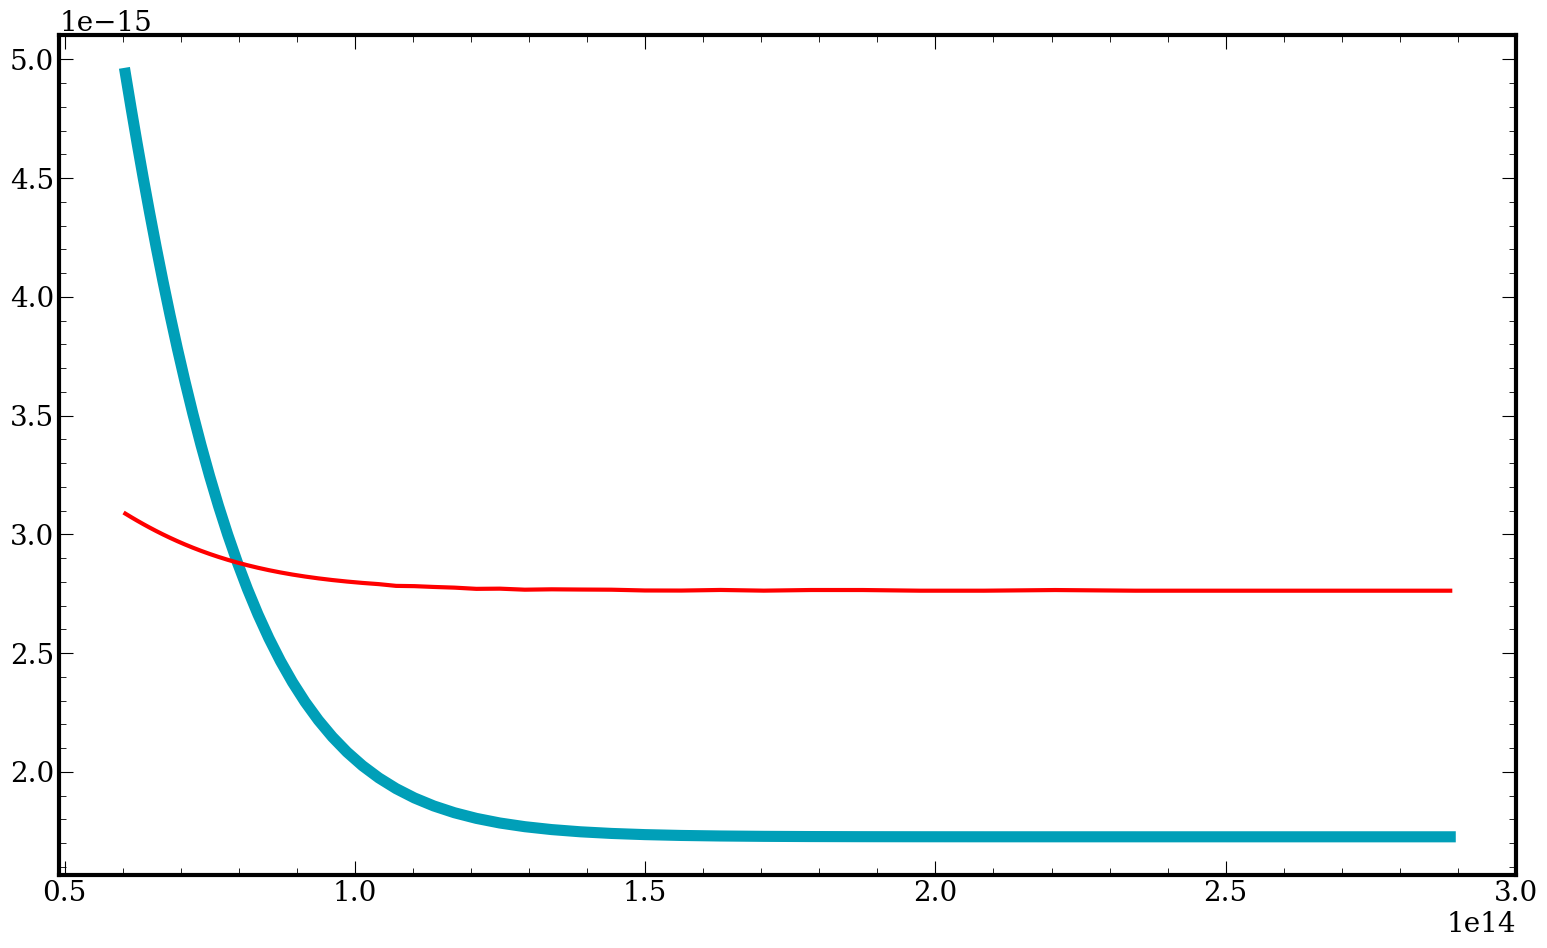

In [9]:
fig, ax = plt.subplots()
print(frequency_bin_centers.shape,fflux.shape)
ax.plot(frequency_bin_centers, fflux, linewidth=8)
ax.plot(frequency_bin_centers, jflux/1e4,color = 'red',linewidth = 3)

[0.83999999 0.84000006 0.84000039 0.840001   0.83984298 0.84000814
 0.84001963 0.83988311 0.83992723 0.84016469 0.8401329  0.84049267
 0.84079153 0.84106028 0.84165066 0.84243751 0.84361069 0.84473162
 0.84644849 0.84816217 0.85034191 0.85283369 0.85576974 0.85869658
 0.86201656 0.86554863 0.86925147 0.87308045 0.87699114 0.88094054
 0.88488879 0.8887999  0.89264328 0.89639305 0.90002878 0.9035342
 0.90689859 0.9101144  0.91317731 0.91608654 0.91884222 0.92144775
 0.92390713 0.92622546 0.92840829 0.93046171 0.93239265 0.93420767
 0.9359128  0.93751467]


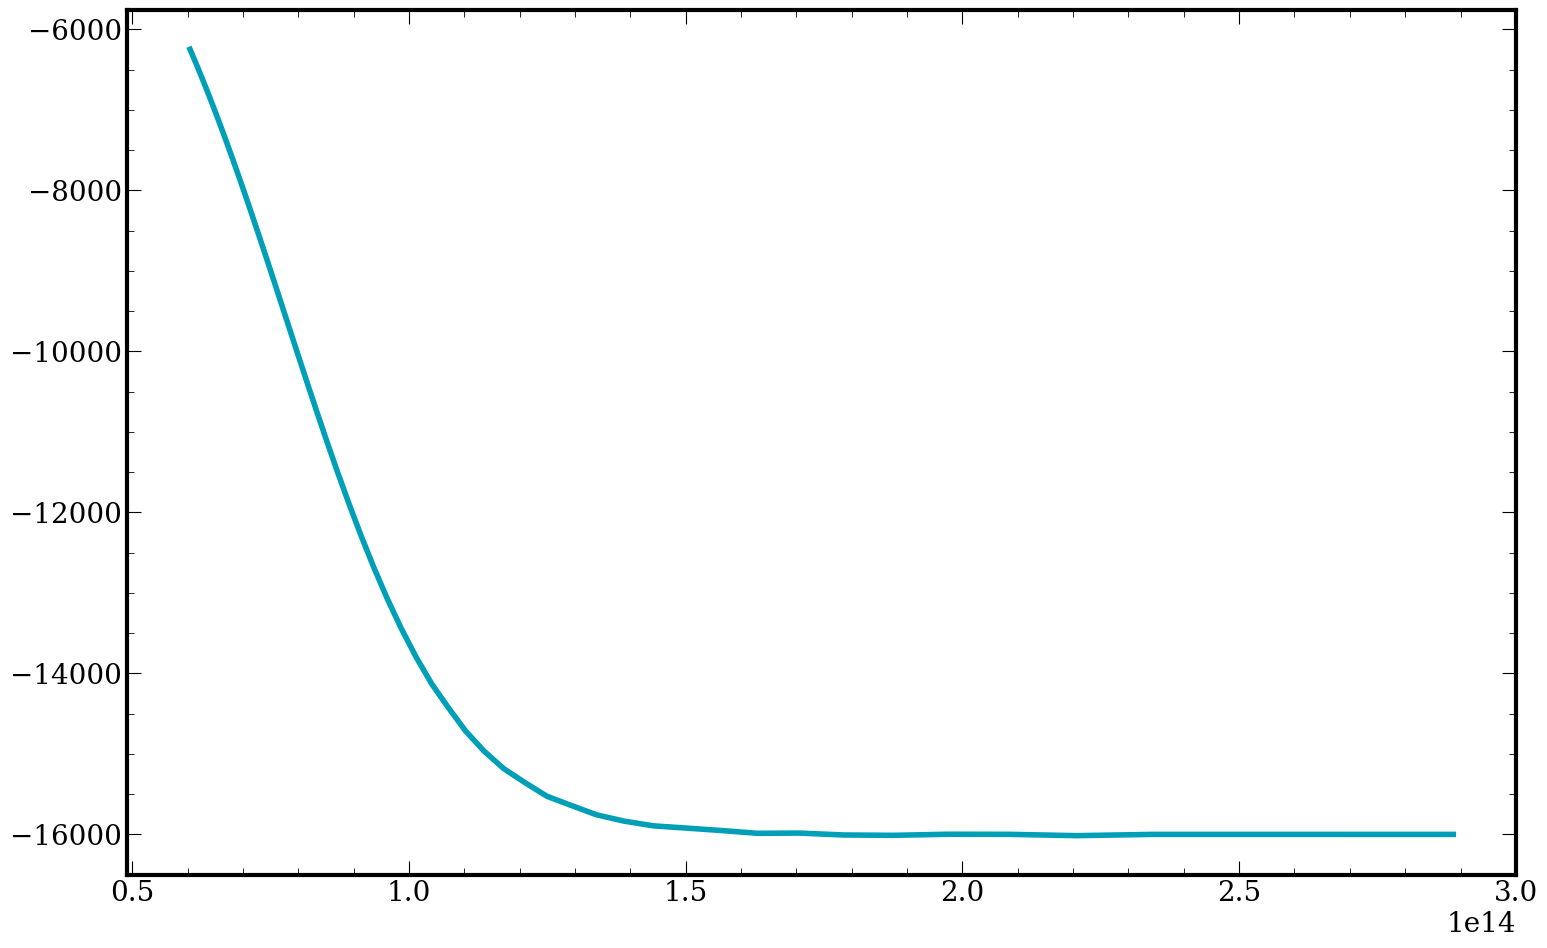

In [7]:
fig, ax = plt.subplots()
ax.plot(frequency_bin_centers, (fflux-(jflux))/fflux, linewidth=4)
print((fflux-(jflux/1e5))/fflux)
#ax.set_ylim(-1e-4,1e-4)
